In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0001.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0002.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0003.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0004.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0005.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0006.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0007.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0008.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0009.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test/Bean/0010.jpg
/kaggle/input/datasets/misrakahmed/vegetable-image

In [15]:
import os 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [3]:
train_path = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train"
test_path="/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test"
val_path="/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation"

In [4]:
print("Train:", os.path.exists(train_path))
print("Test:", os.path.exists(test_path))
print("Validation:", os.path.exists(val_path))

Train: True
Test: True
Validation: True


In [5]:
def count_images(folder_path):

    image_count = {}

    for class_name in os.listdir(folder_path):

        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):

            images = os.listdir(class_path)

            image_count[class_name] = len(images)

    return image_count

In [6]:
train_counts = count_images(train_path)
test_counts = count_images(test_path)
val_counts = count_images(val_path)

print("Train Counts:")
print(train_counts)

print("\nTest Counts:")
print(test_counts)

print("\nValidation Counts:")
print(val_counts)

Train Counts:
{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Test Counts:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation Counts:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


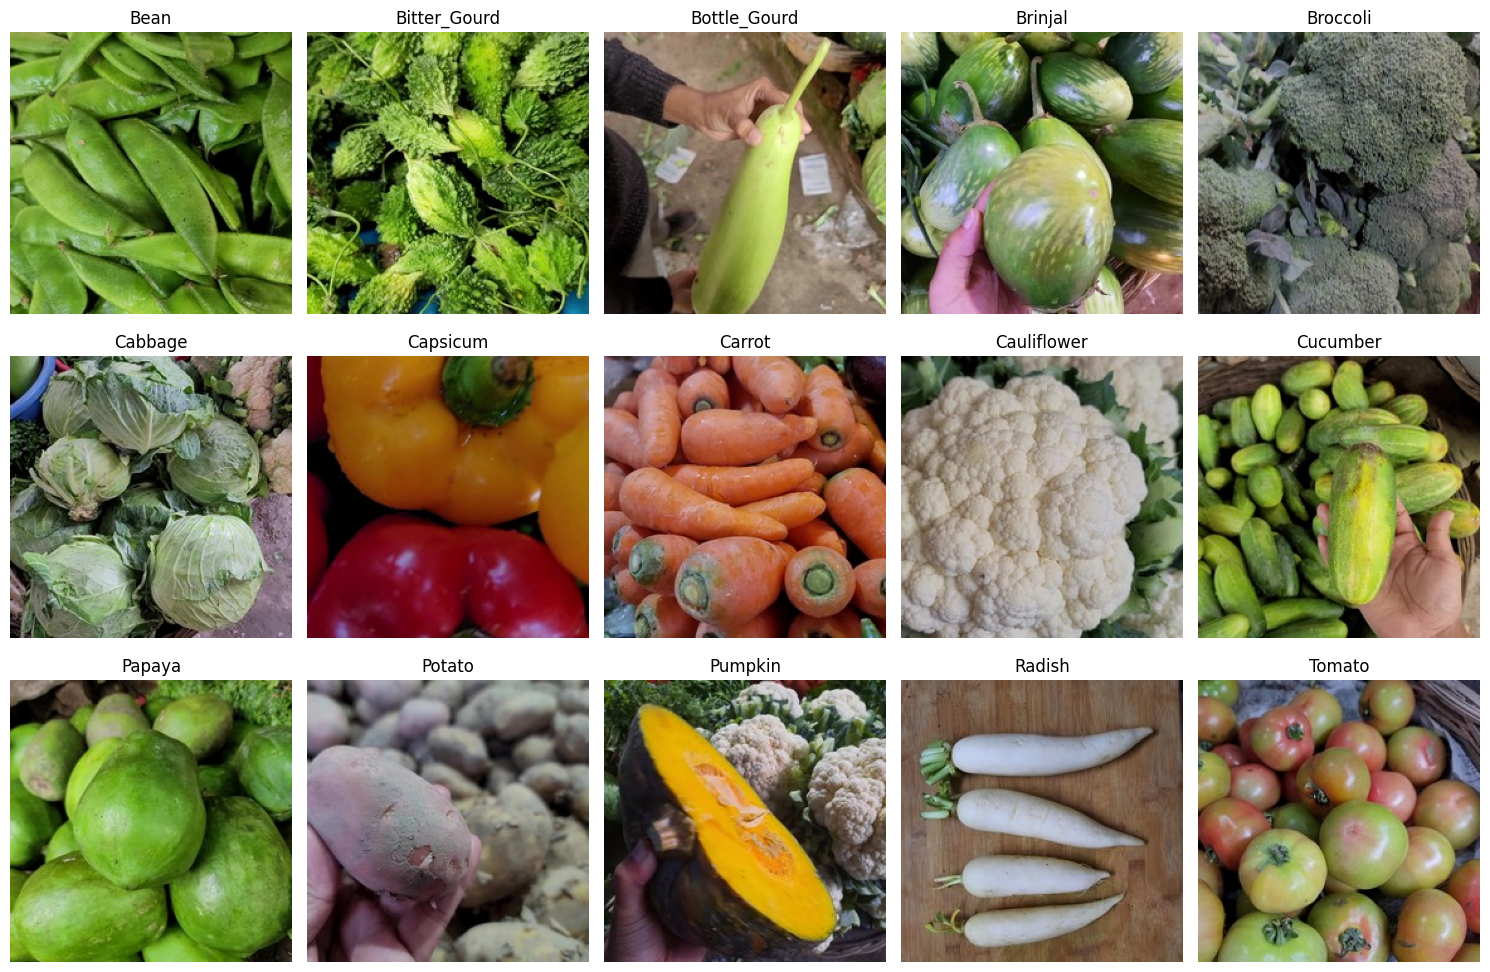

In [29]:
plt.figure(figsize=(15, 10))

class_names = list(train_ds.class_indices.keys())

for i, class_name in enumerate(class_names):

    class_index = train_ds.class_indices[class_name]

    image_index = np.where(train_ds.classes == class_index)[0][0]

    image_path = train_ds.filepaths[image_index]

    image = keras.utils.load_img(image_path)

    plt.subplot(3, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
train_df = pd.DataFrame(
    list(train_counts.items()),
    columns=["Vegetable", "Train Count"]
)

test_df = pd.DataFrame(
    list(test_counts.items()),
    columns=["Vegetable", "Test Count"]
)

val_df = pd.DataFrame(
    list(val_counts.items()),
    columns=["Vegetable", "Validation Count"]
)


In [8]:
summary_df = train_df.merge(test_df, on="Vegetable")
summary_df = summary_df.merge(val_df, on="Vegetable")

summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


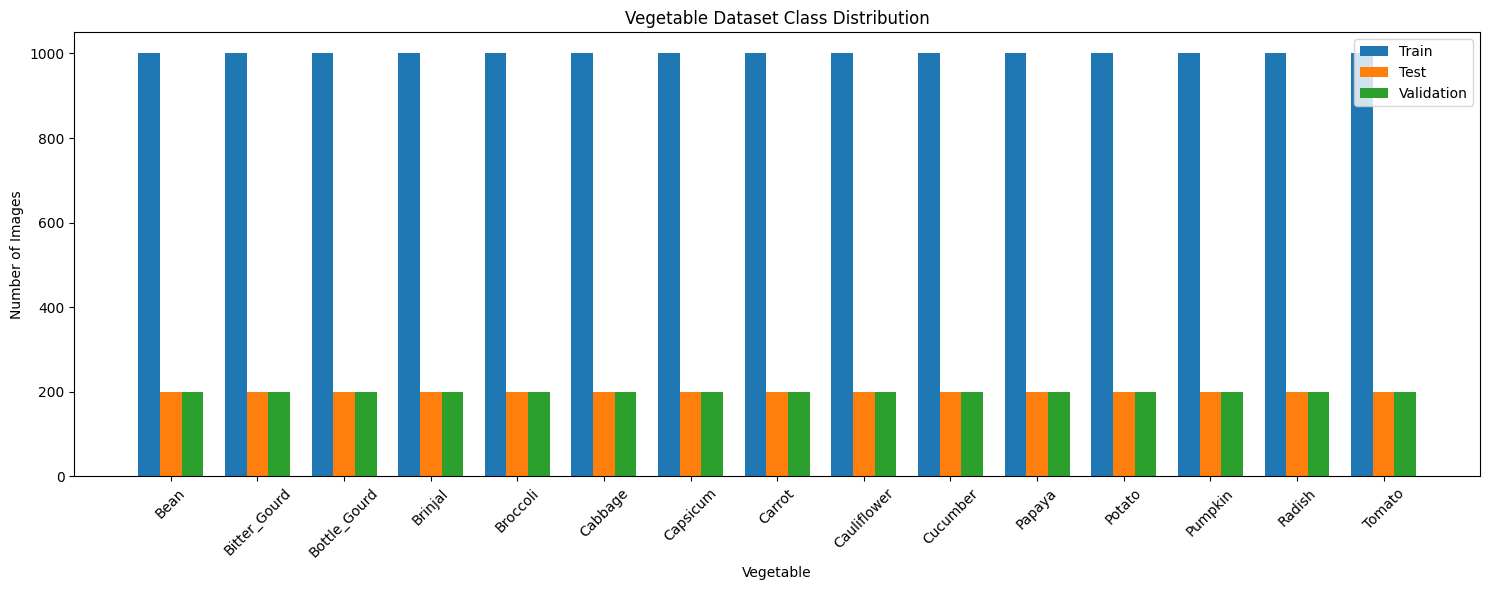

In [9]:
plt.figure(figsize=(15, 6))

x = np.arange(len(summary_df["Vegetable"]))
width = 0.25

plt.bar(x - width, summary_df["Train Count"],
        width, label="Train")

plt.bar(x, summary_df["Test Count"],
        width, label="Test")

plt.bar(x + width, summary_df["Validation Count"],
        width, label="Validation")

plt.xlabel("Vegetable")
plt.ylabel("Number of Images")
plt.title("Vegetable Dataset Class Distribution")

plt.xticks(x, summary_df["Vegetable"], rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

## data is balanced all classes has the same number of elements 


In [10]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

In [11]:
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [12]:
train_ds = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

Found 12000 images belonging to 15 classes.


In [13]:
val_ds = val_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42
)

Found 3000 images belonging to 15 classes.


In [14]:
print("Training images:", train_ds.samples)
print("Validation images:", val_ds.samples)

print("Classes:", train_ds.class_indices)

Training images: 12000
Validation images: 3000
Classes: {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


In [17]:
model = Sequential()

model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(32, (3, 3), activation="relu"))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation="relu"))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(128, (3, 3), activation="relu"))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(512, activation="relu"))
model.add(Dropout(0.5))

model.add(Dense(15, activation="softmax"))

In [18]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=11,
    epochs=20,
    callbacks=[early_stop]
)

In [24]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.9833 - loss: 0.0714
Validation Loss: 0.07140777260065079
Validation Accuracy: 0.9833333492279053


In [25]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


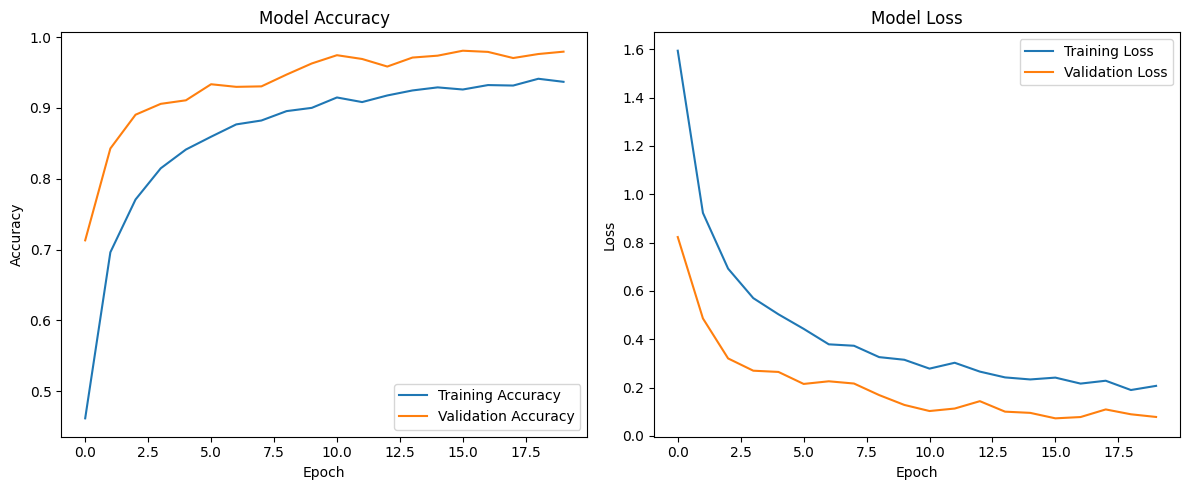

In [26]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
test_datagen = ImageDataGenerator(
    rescale=1./255
)

test_ds = test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 15 classes.


In [28]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 269s 3s/step - accuracy: 0.9783 - loss: 0.0690
Test Loss: 0.06897597759962082
Test Accuracy: 0.9783333539962769


In [30]:
model.save("vegetable_classifier.keras")